# ROMS, CTD, wind, and chlorophyll

Compare CalCOFI and Plumes and Blooms (PnB) CTD measurements with ROMS at 40–60 m. Create plots for PnB alone and for both sources together. All cast-loading code is in this notebook; the existing data files are read in place.

## Imports

Load the libraries for reading data, calculating seawater properties, and plotting maps.

In [1]:
from pathlib import Path

import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
import gsw
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Geod, Transformer
from scipy.interpolate import griddata
from scipy.spatial import QhullError
import shapely
from shapely.geometry import Point, box
from shapely.ops import linemerge, transform
import xarray as xr

## Paths and settings

Set input folders, comparison depths, distance limits, and averaging windows.

In [2]:
analysis_directory = Path('/home/eli2883/ms274/roms_ctd_analysis')
source_directory = Path('/home/eli2883/SIEVE')
inventory_directory = source_directory / 'results/roms_ctd_validation/ussw1/southern_california_bight'
roms_directory = Path('/mnt/backup2/uploads')
output_directory = analysis_directory / 'outputs'
figure_directory = analysis_directory / 'figures'
output_directory.mkdir(exist_ok=True)
figure_directory.mkdir(exist_ok=True)

comparison_depths = np.array([40., 45., 50., 55., 60.])
max_depth_gap = 2  # largest CTD gap, metres
max_distance = 1  # farthest model cell, kilometres
west, east, south, north = -121, -116.5, 31.5, 35

labels = {
    'temperature': 'Potential temperature (°C)',
    'salinity': 'Practical Salinity (PSS-78)',
    'spiciness': 'Spiciness0 (kg/m³)',
    'oxygen': 'Dissolved oxygen (mmol/m³)',
}
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12})
project_data = analysis_directory.parent / 'ms274_project' / 'data'
wind_directory = project_data / 'wind'
chlorophyll_directory = project_data / 'chlorophyll'
natural_earth = Path.home() / '.local/share/cartopy/shapefiles/natural_earth/physical'
coast_half_length_km = 10
wind_grid_spacing = 0.25

# hours before the cast; minimum six-hourly records
wind_windows = {'wind_6h': (6, 1), 'wind_7d': (168, 23), 'wind_14d': (336, 45)}
# first day, excluded last day, minimum daily records
chlorophyll_windows = {
    'chlorophyll_same_day': (0, 1, 1),
    'chlorophyll_7d': (-7, 0, 6),
    'chlorophyll_14d': (-14, 0, 12),
}
window_labels = {
    'wind_6h': '6 h', 'wind_7d': '7 d', 'wind_14d': '14 d',
    'chlorophyll_same_day': 'Same day',
    'chlorophyll_7d': 'Preceding 7 d', 'chlorophyll_14d': 'Preceding 14 d',
}

plot_groups = {'pnb': ['pnb'], 'combined': ['calcofi', 'pnb']}
plot_titles = {'pnb': 'Plumes and Blooms', 'combined': 'CalCOFI + Plumes and Blooms'}
plot_variables = {'pnb': ['salinity', 'oxygen'], 'combined': list(labels)}
source_names = {'calcofi': 'CalCOFI', 'pnb': 'Plumes and Blooms'}

## Casts

Select CalCOFI and PnB casts from 1998–2016 with usable dates and positions. Keep the saved quality exclusions. Check PnB duplicates by filename and exclude conflicting header/file dates.

In [ ]:
calcofi = pd.read_csv(inventory_directory / 'profile_selection.csv', low_memory=False)
selected = calcofi['selected_for_comparison']
valid_time = ~calcofi['time_needs_review']
calcofi = calcofi.loc[selected & valid_time].copy()
calcofi['source'] = 'calcofi'
calcofi['cast_id'] = calcofi['profile_id']
calcofi['cast_time'] = pd.to_datetime(calcofi['time_representative_utc'], format='mixed', utc=True)

# observed position, otherwise nominal
has_latitude = calcofi['observed_latitude'].notna()
has_longitude = calcofi['observed_longitude'].notna()
has_position = has_latitude & has_longitude
calcofi['latitude'] = calcofi['observed_latitude'].where(has_position, calcofi['nominal_latitude'])
calcofi['longitude'] = calcofi['observed_longitude'].where(has_position, calcofi['nominal_longitude'])

pnb = pd.read_csv(inventory_directory / 'ctd_source_inventory.csv', low_memory=False)
selected_pnb = (
    pnb['source_family'].eq('pnb')
    & pnb['record_kind'].eq('profile')
    & pnb['integration_status'].eq('ready')
    & pnb['integration_duplicate_of'].isna()
    & ~pnb['time_needs_review']
)
pnb = pnb.loc[selected_pnb].copy()
pnb['filename'] = [Path(path).name for path in pnb['source_path']]
print('Repeated PnB filenames:', pnb.loc[pnb['filename'].duplicated(), 'filename'].tolist())
pnb = pnb.drop_duplicates('filename')
pnb['source'] = 'pnb'
pnb['cast_id'] = pnb['target_id']
pnb['cast_time'] = pd.to_datetime(pnb['cast_time_utc'], format='mixed', utc=True)

# Do not guess which date is correct when the file and header disagree.
file_dates = pnb['filename'].str.extract(r'_X([0-9]{6})', expand=False)
file_dates = pd.to_datetime(file_dates, format='%y%m%d', utc=True)
date_difference = (file_dates - pnb['cast_time'].dt.normalize()).abs()
conflicting_dates = date_difference > pd.Timedelta(days=1)
print('PnB date conflicts excluded:', conflicting_dates.sum())
pnb = pnb.loc[~conflicting_dates]

columns = ['cast_id', 'source', 'cast_time', 'latitude', 'longitude']
casts = pd.concat([calcofi[columns], pnb[columns + ['source_path']]], ignore_index=True)
casts['cast_time'] = casts['cast_time'].dt.tz_localize(None)  # UTC, matching NetCDF
valid_year = casts['cast_time'].dt.year.between(1998, 2016)
inside_latitude = casts['latitude'].between(south, north)
inside_longitude = casts['longitude'].between(west, east)
casts = casts.loc[valid_year & inside_latitude & inside_longitude]
casts = casts.reset_index(drop=True)
casts['cast_date'] = casts['cast_time'].dt.strftime('%Y-%m-%d')
display(casts.groupby('source').size().rename('casts'))

Repeated PnB filenames: []
PnB date conflicts excluded: 34


source
calcofi    2964
pnb         959
Name: casts, dtype: int64

## Nearest wet ROMS cells

Find the nearest ocean grid cell for each cast. Keep matches within 1 km and with water at least 60 m deep.

In [4]:
grid = xr.load_dataset(roms_directory / 'USSW1_grd_Eli.nc') #use the grid Faycal made for me
latitude_grid = grid['lat_rho'].values
longitude_grid = grid['lon_rho'].values
wet_grid = grid['mask_rho'].values == 1

wet_eta, wet_xi = np.where(wet_grid)
wet_latitude = latitude_grid[wet_grid]
wet_longitude = longitude_grid[wet_grid]
position_matches = {}
positions = casts[['latitude', 'longitude']].drop_duplicates()
for cast in positions.itertuples():
    # cast-to-grid coordinate pairs
    cast_longitudes = np.full(wet_longitude.size, cast.longitude)
    cast_latitudes = np.full(wet_latitude.size, cast.latitude)
    longitude_pairs = np.stack([cast_longitudes, wet_longitude])
    latitude_pairs = np.stack([cast_latitudes, wet_latitude])
    distances = gsw.distance(longitude_pairs, latitude_pairs, axis=0)
    nearest = distances.argmin()
    position_matches[(cast.latitude, cast.longitude)] = (wet_eta[nearest], wet_xi[nearest])

indices = []
for cast in casts.itertuples():
    position = (cast.latitude, cast.longitude)
    indices.append(position_matches[position])
casts[['eta', 'xi']] = indices
casts['model_latitude'] = latitude_grid[casts['eta'], casts['xi']]
casts['model_longitude'] = longitude_grid[casts['eta'], casts['xi']]
longitude_pairs = np.stack([casts['longitude'], casts['model_longitude']])
latitude_pairs = np.stack([casts['latitude'], casts['model_latitude']])
distance_m = gsw.distance(longitude_pairs, latitude_pairs, axis=0)
casts['distance_km'] = distance_m.ravel() / 1000  # metres to kilometres
casts['model_depth'] = grid['h'].values[casts['eta'], casts['xi']]
deep_enough = casts['model_depth'] >= comparison_depths.max()
close_enough = casts['distance_km'] <= max_distance
casts = casts.loc[deep_enough & close_enough].reset_index(drop=True)

## Depth matching

Match measurements to five depths without extrapolating or filling gaps over 2 m. For PnB, use the descent through the first maximum depth. Exclude files containing a return to the surface between deep descents.

In [5]:
def interpolate_profile(depth, values):
    profile = pd.DataFrame({'depth': depth, 'value': values})
    profile = profile.replace([np.inf, -np.inf], np.nan).dropna()
    profile = profile.groupby('depth')['value'].mean()  # repeated depths averaged
    if len(profile) < 2:
        return np.full(len(comparison_depths), np.nan)

    depths = profile.index.to_numpy()
    values = profile.to_numpy()
    interpolated = np.interp(comparison_depths, depths, values, left=np.nan, right=np.nan)
    for index, target_depth in enumerate(comparison_depths):
        if target_depth in depths:
            continue  # exact observed depth
        if target_depth < depths[0] or target_depth > depths[-1]:
            continue  # outside observed range
        shallower = depths[depths < target_depth].max()
        deeper = depths[depths > target_depth].min()
        if deeper - shallower > max_depth_gap:
            interpolated[index] = np.nan  # gap exceeds the allowed spacing
    return interpolated


def profile_difference(model, observed):
    # rows = casts, columns = depths
    model = np.where(np.isfinite(model), model, np.nan)
    observed = np.where(np.isfinite(observed), observed, np.nan)
    differences = model - observed
    return np.mean(differences, axis=-1)  # signed mean; all five depths required

# quick depth checks
assert profile_difference(np.ones(5), np.ones(5)) == 0
assert profile_difference(np.ones(5), 2 * np.ones(5)) == -1
assert np.isnan(interpolate_profile([40, 60], [1, 5])[1:4]).all()


def pnb_downcast(profile):
    depth = profile['depth_m'].to_numpy()
    deep_rows = np.flatnonzero(depth >= 10)
    # A return to 5 m between deep descents indicates multiple excursions.
    if len(deep_rows) > 0:
        between_descents = depth[deep_rows[0]:deep_rows[-1] + 1]
        if np.any(between_descents <= 5):
            return None
    return profile.iloc[:np.nanargmax(depth) + 1]


assert np.isclose(interpolate_profile([44, 46], [2, 4])[1], 3)
assert np.isnan(interpolate_profile([43, 47], [2, 4])[1])
single_descent = pd.DataFrame({'depth_m': [1, 10, 60, 80, 40, 1]})
assert pnb_downcast(single_descent)['depth_m'].tolist() == [1, 10, 60, 80]
assert pnb_downcast(pd.concat([single_descent, single_descent])) is None

## Read CTD profiles

Read CalCOFI in chunks to limit memory use. PnB files have a short text header followed by whitespace-separated measurements. Read their columns by position because some header names repeat.

In [6]:
def read_pnb_profile(path):
    """Read PnB depth, salinity, and oxygen in their original units."""
    with Path(path).open() as file:
        header = {}
        for line in file:
            line = line.strip()
            if line.startswith('/end_header'):
                break
            if line.startswith('/') and '=' in line:
                name, value = line[1:].split('=', 1)
                header[name.lower()] = value
        native = pd.read_csv(file, header=None, sep=r'\s+', comment='!',
                             na_values=header['missing'])

    fields = [name.strip().lower() for name in header['fields'].split(',')]
    columns = {'depth': 'depth_m', 'sal': 'salinity', 'oxygen': 'oxygen'}
    profile = pd.DataFrame(index=native.index)
    for field, name in columns.items():
        if field in fields:
            profile[name] = native.iloc[:, fields.index(field)]
    return profile


# small chunks from the large CalCOFI file
profile_columns = ['profile_id', 'Depth', 'Pressure', 'PrQ', 'Temp1', 'Temp1Q',
                   'Salt1_Corr', 'Salt1Q', 'Ox1_StaCorr', 'Ox1Q']
calcofi_ids = set(casts.loc[casts['source'].eq('calcofi'), 'cast_id'])
profile_file = source_directory / 'data/processed/calcofi_ctd_1998_2016/profiles.csv.gz'
profile_parts = []
for part in pd.read_csv(profile_file, usecols=profile_columns, chunksize=200_000,
                        na_values=[' ', 'NaN', '-99', '-999']):
    selected_cast = part['profile_id'].isin(calcofi_ids)
    near_depths = part['Depth'].between(35, 65)
    keep = selected_cast & near_depths
    profile_parts.append(part.loc[keep])
calcofi_profiles = pd.concat(profile_parts)
calcofi_profiles = calcofi_profiles.groupby('profile_id')

## Prepare CTD measurements

Apply CalCOFI sensor flags and calculate potential temperature and spiciness. PnB supplies salinity and sometimes oxygen; its temperature scale is undocumented, so PnB temperature and spiciness stay missing. Oxygen in both sources is converted from mL/L to mmol/m³. Match available measurements to the five depths.

In [7]:
# rows = casts, columns = depths
observed = {}
for name in labels:
    observed[name] = np.full((len(casts), len(comparison_depths)), np.nan)
multiple_descents = 0
for index, cast in casts.iterrows():
    if cast.source == 'calcofi':
        if cast.cast_id not in calcofi_profiles.groups:
            continue
        profile = calcofi_profiles.get_group(cast.cast_id)
        depth = profile['Depth'].to_numpy()
        # primary sensor quality flags
        good_pressure = ~profile['PrQ'].isin([8, 9])
        good_salinity = good_pressure & ~profile['Salt1Q'].isin([2, 8, 9])
        good_temperature = good_salinity & ~profile['Temp1Q'].isin([2, 8, 9])
        good_oxygen = good_pressure & ~profile['Ox1Q'].isin([2, 8, 9])
        salinity = profile['Salt1_Corr'].where(good_salinity).to_numpy()
        # GSW temperature and salinity conversions
        pressure = profile['Pressure'].to_numpy()
        absolute_salinity = gsw.SA_from_SP(salinity, pressure, cast.longitude, cast.latitude)
        temperature = gsw.pt0_from_t(absolute_salinity, profile['Temp1'].to_numpy(), pressure)
        temperature = np.where(good_temperature, temperature, np.nan)
        conservative_temperature = gsw.CT_from_pt(absolute_salinity, temperature)
        # oxygen: mL/L to mmol/m³
        measurements = {
            'temperature': temperature,
            'salinity': salinity,
            'spiciness': gsw.spiciness0(absolute_salinity, conservative_temperature),
            'oxygen': (profile['Ox1_StaCorr'] * 44.6596).where(good_oxygen).to_numpy(),
        }
    else:
        profile = read_pnb_profile(cast.source_path)
        profile = pnb_downcast(profile)
        if profile is None:
            multiple_descents += 1
            continue
        depth = profile['depth_m'].to_numpy()
        measurements = {}
        if 'salinity' in profile:
            measurements['salinity'] = profile['salinity'].to_numpy()
        if 'oxygen' in profile:
            measurements['oxygen'] = profile['oxygen'].to_numpy() * 44.6596
    for name, values in measurements.items():
        observed[name][index] = interpolate_profile(depth, values)

print('PnB multiple descents excluded:', multiple_descents)
print('CTD profiles read.')

PnB multiple descents excluded: 12
CTD profiles read.


## Read daily ROMS profiles

Read each model day once and extract the matched cast locations. Calculate model spiciness using the same method as the CTD data.

In [8]:
model_values = {}
for name in labels:
    model_values[name] = np.full((len(casts), len(comparison_depths)), np.nan)
has_salinity = np.isfinite(observed['salinity']).any(axis=1)
has_oxygen = np.isfinite(observed['oxygen']).any(axis=1)
model_casts = casts.loc[has_salinity | has_oxygen]
days = model_casts.groupby('cast_date', sort=True)
for day_number, (date, day_casts) in enumerate(days, 1):
    path = roms_directory / pd.Timestamp(date).strftime('z_ussw1_avg.Y%YM%mD%d.nc')
    cast_indices = day_casts.index.to_numpy()
    # paired grid positions, one column per cast
    rows = xr.DataArray(day_casts['eta'].to_numpy(), dims='cast')
    columns = xr.DataArray(day_casts['xi'].to_numpy(), dims='cast')
    with xr.open_dataset(path) as source:
        profiles = source[['temp', 'salt', 'O2']].sel(depth=-comparison_depths)
        profiles = profiles.isel(eta_rho=rows, xi_rho=columns)
        profiles = profiles.transpose('cast', 'depth').load()
    model_values['temperature'][cast_indices] = profiles['temp'].values
    model_values['salinity'][cast_indices] = profiles['salt'].values
    model_values['oxygen'][cast_indices] = profiles['O2'].values
    # one latitude/longitude per row, shared across depths
    model_latitudes = day_casts['model_latitude'].to_numpy().reshape(-1, 1)
    model_longitudes = day_casts['model_longitude'].to_numpy().reshape(-1, 1)
    pressure = gsw.p_from_z(-comparison_depths, model_latitudes)
    absolute_salinity = gsw.SA_from_SP(profiles['salt'].values, pressure, model_longitudes, model_latitudes)
    conservative_temperature = gsw.CT_from_pt(absolute_salinity, profiles['temp'].values)
    model_values['spiciness'][cast_indices] = gsw.spiciness0(absolute_salinity, conservative_temperature)
    if day_number % 100 == 0 or day_number == len(days):
        print(f'{day_number} / {len(days)} model days read')

100 / 895 model days read


200 / 895 model days read


300 / 895 model days read


400 / 895 model days read


500 / 895 model days read


600 / 895 model days read


700 / 895 model days read


800 / 895 model days read


895 / 895 model days read


## Calculate model-minus-CTD differences

Average the signed model-minus-CTD differences across all five paired depths for each cast and variable. Positive values mean ROMS is higher than CTD; negative values mean ROMS is lower. Keep missing variables separate.

In [9]:
results = casts[['cast_id', 'source', 'cast_time', 'cast_date', 'latitude', 'longitude', 'eta', 'xi', 'distance_km']].copy()
for name in labels:
    results[f'{name}_difference'] = profile_difference(model_values[name], observed[name])
difference_columns = [f'{name}_difference' for name in labels]
results = results.dropna(subset=difference_columns, how='all')
display(results.groupby('source')[difference_columns].count())

,temperature_difference,salinity_difference,spiciness_difference,oxygen_difference
source,,,,
calcofi,2345,2345,2345,2310
pnb,0,805,0,413


### Difference distributions

Show the spread of mean model-minus-CTD differences for each variable, with a dashed line marking the median.

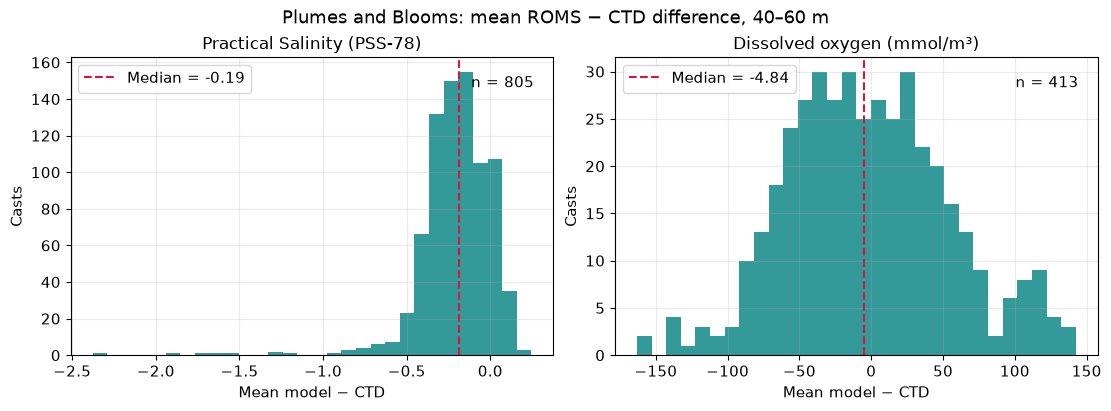

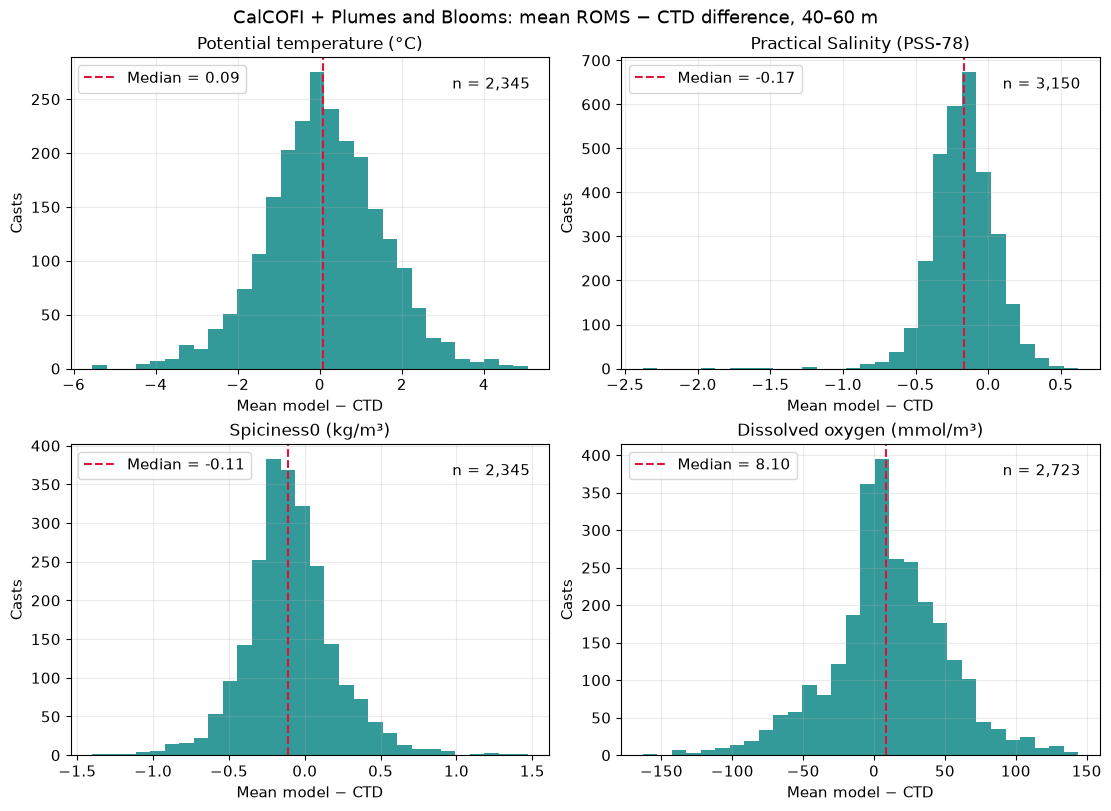

In [10]:
for group, sources in plot_groups.items():
    plot_data = results.loc[results['source'].isin(sources)]
    variables = plot_variables[group]
    fig, axes = plt.subplots(len(variables) // 2, 2, figsize=(11, 4 * (len(variables) // 2)),
                             layout='constrained')
    for ax, name in zip(axes.flat, variables):
        values = plot_data[f'{name}_difference'].dropna()
        ax.hist(values, bins=30, color='teal', alpha=0.8)
        ax.axvline(values.median(), color='crimson', linestyle='--',
                   label=f'Median = {values.median():.2f}')
        ax.set(title=labels[name], xlabel='Mean model − CTD', ylabel='Casts')
        ax.text(0.96, 0.9, f'n = {len(values):,}', transform=ax.transAxes, ha='right')
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f'{plot_titles[group]}: mean ROMS − CTD difference, 40–60 m')
    fig.savefig(figure_directory / f'difference_40_60m_{group}.png', dpi=300, bbox_inches='tight')
    plt.show()

### Example profiles

Show one profile per included source. Use a labeled partial profile when the 2 m gap rule prevents a complete comparison.

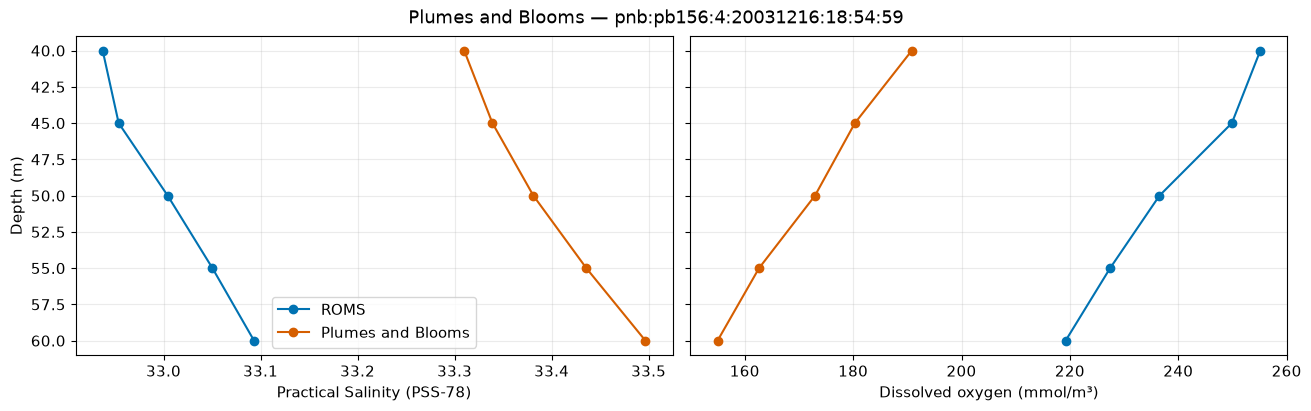

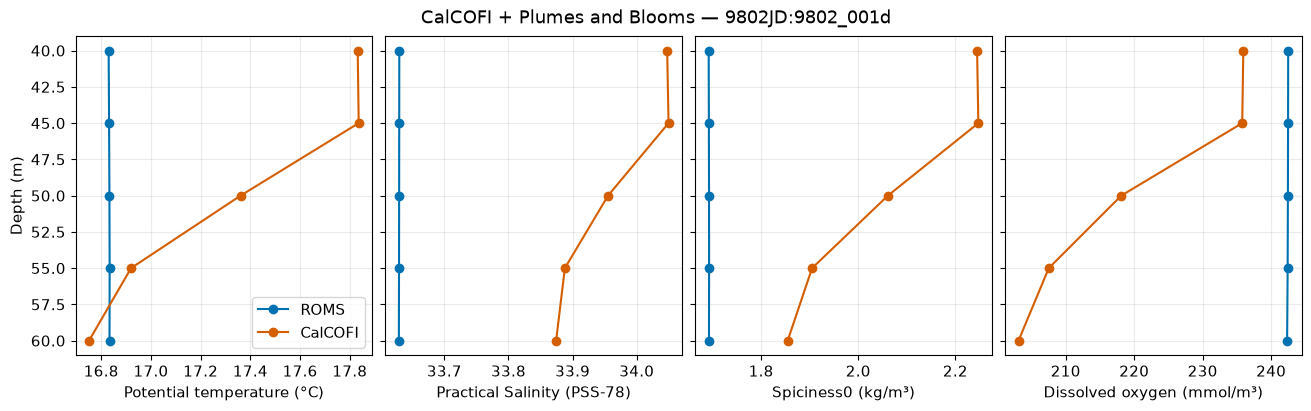

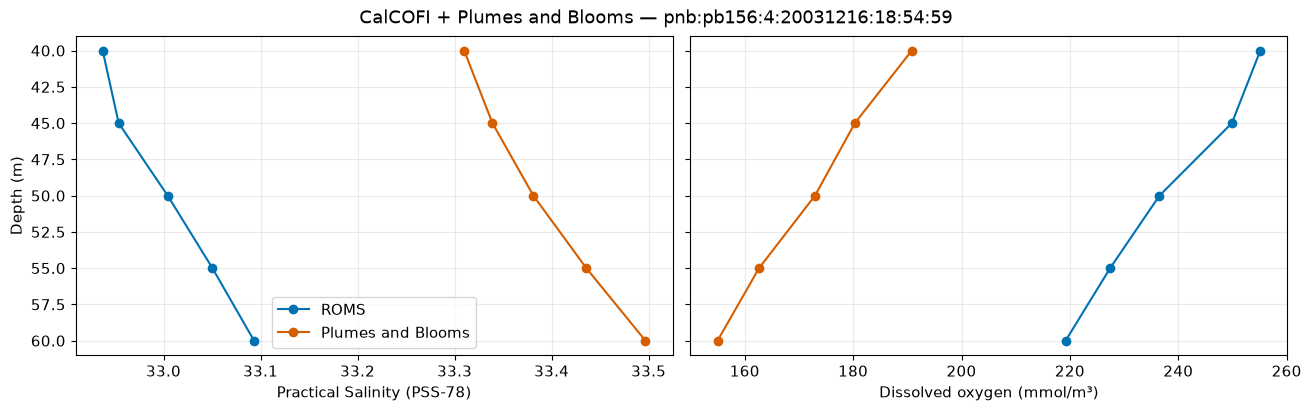

In [5]:
for group, sources in plot_groups.items():
    for source_name in sources:
        variables = ['salinity', 'oxygen'] if source_name == 'pnb' else list(labels)
        difference_columns = [f'{name}_difference' for name in variables]
        complete = results[difference_columns].notna().all(axis=1)
        examples = results.index[results['source'].eq(source_name) & complete]
        if len(examples) == 0:
            examples = results.index[results['source'].eq(source_name) & results['salinity_difference'].notna()]
        profile_note = ''
        if len(examples) == 0:
            # Use a partial profile if no cast has all five paired salinity depths.
            paired_salinity = np.isfinite(observed['salinity']) & np.isfinite(model_values['salinity'])
            examples = casts.index[casts['source'].eq(source_name) & paired_salinity.any(axis=1)]
            profile_note = ' — partial depths'
        if len(examples) > 0:
            example = examples[0]
            fig, axes = plt.subplots(1, len(variables), figsize=(13, 4), sharey=True, layout='constrained')
            for ax, name in zip(axes, variables):
                label = labels[name]
                ax.plot(model_values[name][example], comparison_depths, 'o-', color='#0072B2', label='ROMS')
                ax.plot(observed[name][example], comparison_depths, 'o-', color='#D55E00', label=source_names[source_name])
                ax.set_xlabel(label)
                ax.grid(alpha=0.25)
            axes[0].set_ylabel('Depth (m)')
            axes[0].invert_yaxis()
            axes[0].legend()
            fig.suptitle(f'{plot_titles[group]} — {casts.loc[example, "cast_id"]}{profile_note}')
            fig.savefig(figure_directory / f'profile_{group}_{source_name}.png', dpi=200)
            plt.show()

## Mainland coastline and alongshore direction

For each wet ROMS pixel in the study area, find the nearest point on the mainland coast. Take two coastal points 10 km before and after that point to estimate a smooth alongshore direction. Use geographic bearings so the vector components describe east and north, and orient the vector toward the southeast half of the compass. Each cast uses the direction at its matched ROMS pixel.

In [4]:
conditions = results.set_index('cast_id').copy()
cast_times = conditions['cast_time']
cast_days = pd.to_datetime(conditions['cast_date'])

map_margin = box(west - 2, south - 2, east + 2, north + 2)


def read_regional_geometry(filename):
    pieces = []
    for geometry in Reader(natural_earth / filename).geometries():
        if geometry.intersects(map_margin):
            pieces.append(geometry.intersection(map_margin))
    return shapely.union_all(pieces)


merged_coast = linemerge(read_regional_geometry("ne_10m_coastline.shp"))
# longest connected coastline
mainland = merged_coast.geoms[0]
for coastline in merged_coast.geoms:
    if coastline.length > mainland.length:
        mainland = coastline
land = read_regional_geometry("ne_10m_land.shp")

# local map coordinates in metres
center_latitude = (south + north) / 2
center_longitude = (west + east) / 2
local_crs = f"+proj=aeqd +lat_0={center_latitude} +lon_0={center_longitude} +datum=WGS84 +units=m"
to_local = Transformer.from_crs("EPSG:4326", local_crs, always_xy=True)
to_geographic = Transformer.from_crs(local_crs, "EPSG:4326", always_xy=True)
geodesic = Geod(ellps="WGS84")

# degrees to metres
mainland_m = transform(to_local.transform, mainland)


def coastal_direction(longitude, latitude):
    """Return the east/north components and bearing of the local coast."""
    x, y = to_local.transform(longitude, latitude)
    distance_along = mainland_m.project(Point(x, y))
    half_length = coast_half_length_km * 1000
    before = mainland_m.interpolate(max(0, distance_along - half_length))
    after = mainland_m.interpolate(min(mainland_m.length, distance_along + half_length))
    before_lon, before_lat = to_geographic.transform(before.x, before.y)
    after_lon, after_lat = to_geographic.transform(after.x, after.y)
    bearing, _, _ = geodesic.inv(before_lon, before_lat, after_lon, after_lat)
    if np.cos(np.deg2rad(bearing - 135)) < 0:
        bearing += 180
    bearing = bearing % 360
    return np.sin(np.deg2rad(bearing)), np.cos(np.deg2rad(bearing)), bearing


inside_region = (
    (longitude_grid >= west) & (longitude_grid <= east)
    & (latitude_grid >= south) & (latitude_grid <= north)
)
direction_cells = wet_grid & inside_region
# Include matched cells just outside the boundary when a nearby cast is inside.
direction_cells[conditions['eta'], conditions['xi']] = True
coast_east_grid = np.full(latitude_grid.shape, np.nan)
coast_north_grid = np.full(latitude_grid.shape, np.nan)
coast_bearing_grid = np.full(latitude_grid.shape, np.nan)
grid_rows, grid_columns = np.where(direction_cells)
for row, column in zip(grid_rows, grid_columns):
    east_component, north_component, bearing = coastal_direction(
        longitude_grid[row, column], latitude_grid[row, column],
    )
    coast_east_grid[row, column] = east_component
    coast_north_grid[row, column] = north_component
    coast_bearing_grid[row, column] = bearing

rows = conditions['eta'].to_numpy()
columns = conditions['xi'].to_numpy()
conditions['coast_east'] = coast_east_grid[rows, columns]
conditions['coast_north'] = coast_north_grid[rows, columns]
conditions['coast_bearing_degrees'] = coast_bearing_grid[rows, columns]
print(f'Coastal directions calculated for {len(grid_rows):,} wet ROMS pixels.')


Coastal directions calculated for 135,551 wet ROMS pixels.


### Coastline maps

Show each group's casts over the same ROMS direction grid. Draw one arrow per map tile for readability; every wet pixel in the study area has a calculated direction.

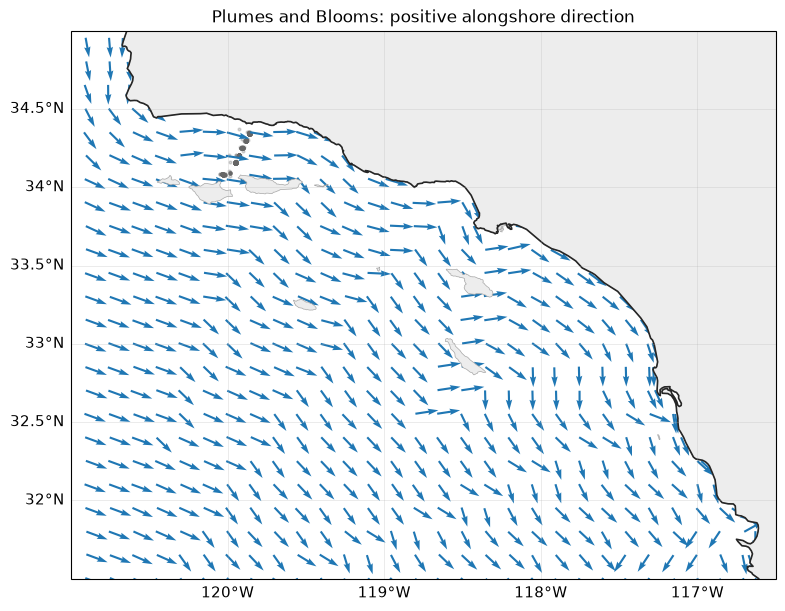

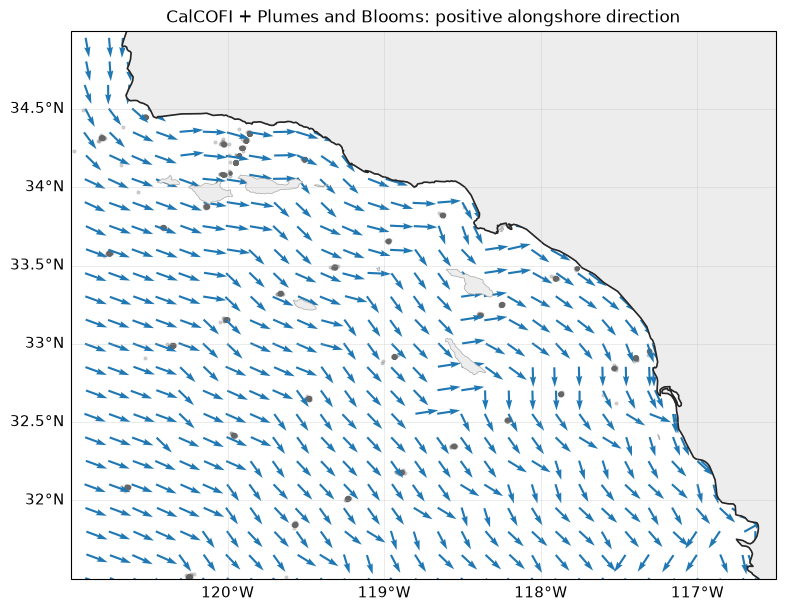

In [5]:
for group, sources in plot_groups.items():
    plot_data = conditions.loc[conditions['source'].isin(sources)]
    data_crs = ccrs.PlateCarree()
    fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": data_crs})
    ax.set_extent([west, east, south, north], crs=data_crs)
    ax.add_geometries([land], data_crs, facecolor="0.93", edgecolor="0.65", linewidth=0.5)
    ax.add_geometries([mainland], data_crs, facecolor="none", edgecolor="0.15", linewidth=1.2)
    ax.scatter(
        plot_data["longitude"], plot_data["latitude"], s=4, color="0.4", alpha=0.25,
        transform=data_crs,
    )
    # one arrow per map tile
    arrow_casts = pd.DataFrame({
        'longitude': longitude_grid[grid_rows, grid_columns],
        'latitude': latitude_grid[grid_rows, grid_columns],
        'coast_bearing_degrees': coast_bearing_grid[grid_rows, grid_columns],
    })
    arrow_tiles = np.floor(arrow_casts[["longitude", "latitude"]] / 0.15)
    arrow_casts = arrow_casts.loc[~arrow_tiles.duplicated()]
    arrow_lon = arrow_casts["longitude"].to_numpy()
    arrow_lat = arrow_casts["latitude"].to_numpy()
    arrow_end_lon, arrow_end_lat, _ = geodesic.fwd(
        arrow_lon, arrow_lat, arrow_casts["coast_bearing_degrees"].to_numpy(),
        np.full(len(arrow_casts), 14_000.0),
    )
    eastward_arrow = arrow_end_lon - arrow_lon
    northward_arrow = arrow_end_lat - arrow_lat
    ax.quiver(
        arrow_lon, arrow_lat, eastward_arrow, northward_arrow,
        transform=data_crs, angles="xy", scale_units="xy", scale=1, width=0.003, color="tab:blue",
    )
    grid = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.35)
    grid.top_labels = False
    grid.right_labels = False
    ax.set_title(f"{plot_titles[group]}: positive alongshore direction")
    fig.savefig(figure_directory / f'coastline_{group}.png', dpi=200)
    plt.show()

## Interpolation and time-window helpers

Interpolate only at the unique wet ROMS cells matched to casts. Missing source pixels are excluded, allowing interpolation across cloud gaps; locations outside the valid source coverage stay missing.

Average available values only when enough records are present. Include the start of each window and exclude its end.

In [14]:
# Shared ROMS cells are interpolated once, then mapped back to each cast.
matched_cells, cast_cell_columns = np.unique(
    conditions[['eta', 'xi']].to_numpy(), axis=0, return_inverse=True,
)
roms_longitudes = longitude_grid[matched_cells[:, 0], matched_cells[:, 1]]
roms_latitudes = latitude_grid[matched_cells[:, 0], matched_cells[:, 1]]
roms_x, roms_y = to_local.transform(roms_longitudes, roms_latitudes)
roms_points = np.column_stack([roms_x, roms_y])


def interpolate_to_roms(source_points, values):
    values = np.asarray(values, dtype=float).ravel()
    # To preserve missing pixels, use these lines instead of the valid-pixel block:
    # values = np.where(np.isfinite(values), values, np.nan)
    # return griddata(source_points, values, roms_points, method='linear', fill_value=np.nan)

    # Use available pixels so interpolation can bridge cloud gaps.
    valid = np.isfinite(values)
    if valid.sum() < 3:
        return np.full(len(roms_points), np.nan)
    try:
        return griddata(
            source_points[valid], values[valid], roms_points,
            method='linear', fill_value=np.nan,
        )
    except QhullError:
        # Points along a single line cannot define a two-dimensional surface.
        return np.full(len(roms_points), np.nan)


def window_mean(values, dates, first_time, excluded_last_time, minimum):
    # start included, end excluded
    first = dates.searchsorted(first_time)
    last = dates.searchsorted(excluded_last_time)
    values_in_window = np.asarray(values)[first:last]
    valid = values_in_window[np.isfinite(values_in_window)]
    if len(valid) < minimum:
        return np.nan
    return valid.mean()


def days_needed(reference_times, preceding_days):
    cast_dates = pd.DatetimeIndex(reference_times.dropna())
    cast_dates = cast_dates.normalize().unique()
    required_days = set()
    for day in cast_dates:
        for offset in range(preceding_days + 1):
            required_days.add(day - pd.Timedelta(days=offset))
    return required_days

# window boundaries and missing records
check_times = pd.to_datetime(['2000-01-01', '2000-01-02'])
assert window_mean([2, 9], check_times, check_times[0], check_times[1], 1) == 2
assert np.isnan(window_mean([2, np.nan], check_times, check_times[0], check_times[1], 2))

## Alongshore wind

Interpolate both wind components to the matched ROMS cells and project them onto each cast's local coast direction. Average the preceding 6 hours, 7 days, and 14 days, requiring at least 80% coverage.

In [15]:
# completed wind files by date
wind_files = {}
for path in wind_directory.glob('CCMP_Wind_Analysis_????????_V03.1_L4.nc'):
    date_text = path.name.split('_')[3]
    date = pd.to_datetime(date_text, format='%Y%m%d')
    wind_files[date] = path

lookback_hours = []
for hours, minimum in wind_windows.values():
    lookback_hours.append(hours)
required_days = days_needed(cast_times, max(lookback_hours) // 24)
margin = wind_grid_spacing / 2  # half-cell margin
wind_subsets = []
for day in sorted(required_days):
    if day not in wind_files:
        continue
    with xr.open_dataset(wind_files[day]) as source:
        subset = source[['uwnd', 'vwnd']].sel(
            latitude=slice(south - margin, north + margin),
            longitude=slice(west + 360 - margin, east + 360 + margin),
        )
        longitude = (subset['longitude'] + 180) % 360 - 180  # west longitudes negative
        wind_subsets.append(subset.assign_coords(longitude=longitude).load())

conditions[list(wind_windows)] = np.nan
if wind_subsets:
    wind = xr.concat(wind_subsets, dim='time').sortby('time')
    wind_times = pd.DatetimeIndex(wind['time'].values)
    wind_lon, wind_lat = np.meshgrid(wind['longitude'].values, wind['latitude'].values)
    wind_x, wind_y = to_local.transform(wind_lon, wind_lat)
    wind_points = np.column_stack([wind_x.ravel(), wind_y.ravel()])
    wind_u = np.full((len(wind_times), len(matched_cells)), np.nan, dtype=np.float32)
    wind_v = np.full_like(wind_u, np.nan)
    for time_index in range(len(wind_times)):
        wind_u[time_index] = interpolate_to_roms(wind_points, wind['uwnd'].isel(time=time_index).values)
        wind_v[time_index] = interpolate_to_roms(wind_points, wind['vwnd'].isel(time=time_index).values)

    for cast, cell_column in zip(conditions.itertuples(), cast_cell_columns):
        # Wind component along this cast's coast direction.
        alongshore = wind_u[:, cell_column] * cast.coast_east + wind_v[:, cell_column] * cast.coast_north
        for window in wind_windows:
            hours, minimum = wind_windows[window]
            start_time = cast.cast_time - pd.Timedelta(hours=hours)
            conditions.at[cast.Index, window] = window_mean(
                alongshore, wind_times, start_time, cast.cast_time, minimum,
            )
print(f'Wind: {len(wind_subsets)} daily files')

Wind: 3796 daily files


## Chlorophyll source grid

Use ocean pixels as interpolation inputs. Daily chlorophyll is interpolated to the same matched ROMS cells as wind, allowing gaps between valid pixels to be filled.

In [16]:
chlorophyll_files = sorted(chlorophyll_directory.glob("occci_scb_??????.nc"))
with xr.open_dataset(chlorophyll_files[0]) as first_month:
    pixel_latitudes = first_month["lat"].values
    pixel_longitudes = first_month["lon"].values

pixel_lon, pixel_lat = np.meshgrid(pixel_longitudes, pixel_latitudes)
# Ocean pixels only; coordinates must follow the same order as the data.
on_land = shapely.intersects_xy(land, pixel_lon, pixel_lat)
ocean_rows, ocean_columns = np.nonzero(~on_land)
ocean_x, ocean_y = to_local.transform(
    pixel_lon[ocean_rows, ocean_columns], pixel_lat[ocean_rows, ocean_columns],
)
chlorophyll_points = np.column_stack([ocean_x, ocean_y])


## Chlorophyll averages

Calculate same-day, preceding 7-day, and preceding 14-day averages, requiring at least 1, 6, and 12 daily values. Preceding windows exclude the cast day; same-day values may include later observations.

In [17]:
lookback_days = []
for start, end, minimum in chlorophyll_windows.values():
    lookback_days.append(-start)
chlorophyll_lookback = max(lookback_days)
required_days = days_needed(cast_days, chlorophyll_lookback)
chlorophyll_days = pd.DatetimeIndex(sorted(required_days))
chlorophyll_values = np.full((len(chlorophyll_days), len(matched_cells)), np.nan, dtype=np.float32)

required_chlorophyll_months = set(chlorophyll_days.strftime("%Y%m"))
for path in chlorophyll_files:
    if path.stem.split("_")[-1] not in required_chlorophyll_months:
        continue
    with xr.open_dataset(path) as source:
        dates = pd.DatetimeIndex(source["time"].values).normalize()
        # monthly dates matched to the full date list
        destination_rows = chlorophyll_days.get_indexer(dates)
        source_rows = np.flatnonzero(destination_rows >= 0)
        matching_rows = destination_rows[source_rows]
        if len(source_rows):
            regional_values = source["chlor_a"].isel(time=source_rows).values
            for day_values, destination_row in zip(regional_values, matching_rows):
                chlorophyll_values[destination_row] = interpolate_to_roms(
                    chlorophyll_points, day_values[ocean_rows, ocean_columns],
                )

conditions[list(chlorophyll_windows)] = np.nan

for cast_id, cell_column in zip(conditions.index, cast_cell_columns):
    cast_day = cast_days.at[cast_id]
    for window in chlorophyll_windows:
        start_day, end_day, minimum = chlorophyll_windows[window]
        start_date = cast_day + pd.Timedelta(days=start_day)
        end_date = cast_day + pd.Timedelta(days=end_day)
        conditions.at[cast_id, window] = window_mean(
            chlorophyll_values[:, cell_column], chlorophyll_days,
            start_date, end_date,
            minimum,
        )

print(f'Chlorophyll: {len(required_chlorophyll_months)} requested months')

Chlorophyll: 201 requested months


## Correlation plots

Plot each environmental measure against the mean model-minus-CTD difference, with the correlation and cast count in each panel. Repeated cruises and overlapping windows limit independence.

In [18]:
def plot_correlations(plot_data, variables, group, windows, title, xlabel, color):
    fig, axes = plt.subplots(len(variables), 3, figsize=(12, 2.75 * len(variables)), sharey='row', layout='constrained')
    rows = []
    for row, variable in enumerate(variables):
        label = labels[variable]
        for column, window in enumerate(windows):
            ax = axes[row, column]
            difference = f'{variable}_difference'
            paired = plot_data[[window, difference]]
            paired = paired.replace([np.inf, -np.inf], np.nan).dropna()
            correlation = np.nan
            enough_pairs = len(paired) >= 3
            varying_values = paired[window].nunique() > 1 and paired[difference].nunique() > 1
            if enough_pairs and varying_values:
                correlation = paired[window].corr(paired[difference])
            rows.append({'variable': variable, 'window': window, 'pearson_r': correlation, 'n': len(paired)})
            ax.scatter(paired[window], paired[difference], s=11, color=color, alpha=0.3)
            ax.text(0.97, 0.96, f'r = {correlation:.2f}\nn = {len(paired):,}',
                    transform=ax.transAxes, ha='right', va='top')
            ax.grid(alpha=0.25)
            if row == 0:
                ax.set_title(window_labels[window])
            if column == 0:
                ax.set_ylabel(f'Mean model − CTD\n{label}', fontsize=10)
            if row == len(variables) - 1:
                ax.set_xlabel(xlabel)
    fig.suptitle(f'{plot_titles[group]}: {title.lower()} and mean ROMS − CTD difference, 40–60 m')
    fig.savefig(figure_directory / f'{title.lower()}_difference_{group}.png', dpi=300, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rows)

## Create figures and save results

Create PnB-only and combined figures from the same calculated values. Combined temperature and spiciness use CalCOFI observations only. Save separate correlation tables and one combined table of cast results.

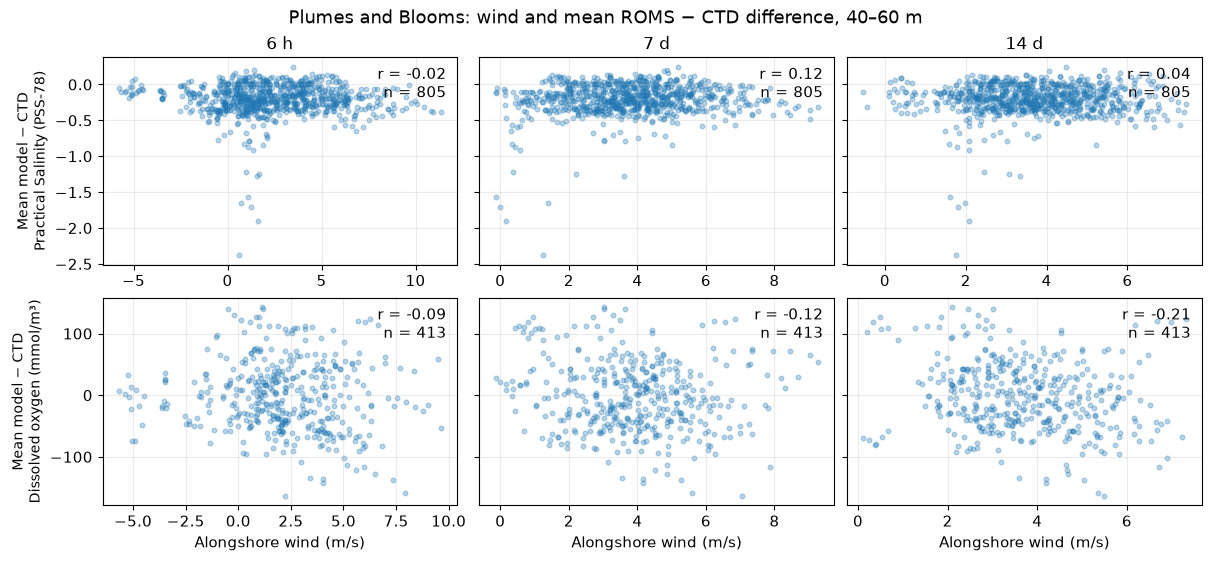

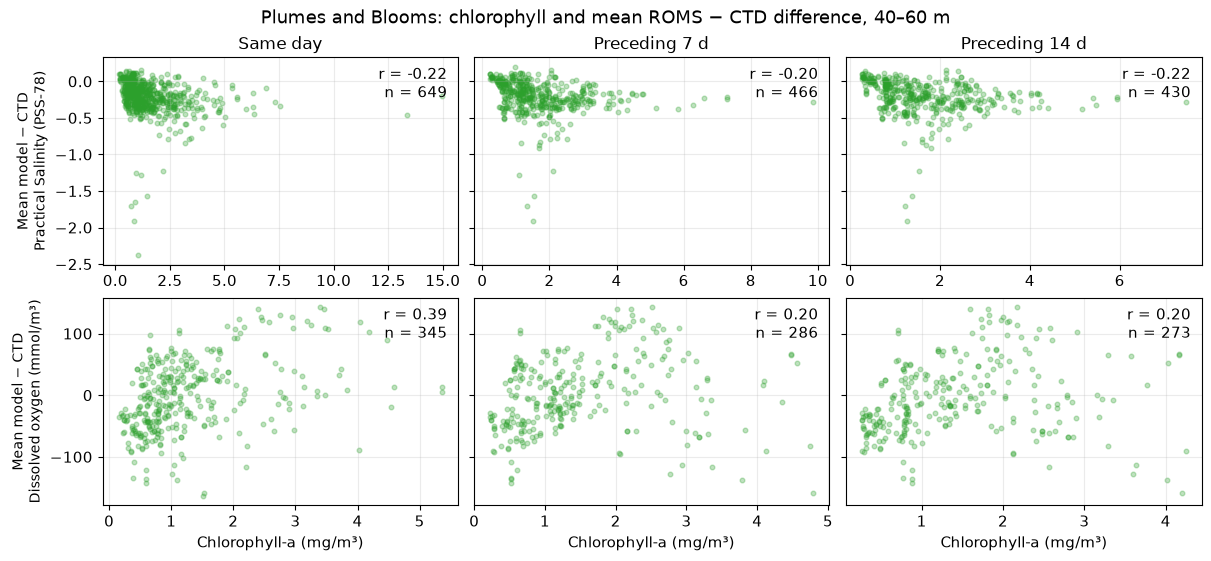

Plumes and Blooms


,variable,window,pearson_r,n
0,salinity,wind_6h,-0.019,805
1,salinity,wind_7d,0.115,805
2,salinity,wind_14d,0.045,805
3,oxygen,wind_6h,-0.085,413
4,oxygen,wind_7d,-0.124,413
5,oxygen,wind_14d,-0.208,413
6,salinity,chlorophyll_same_day,-0.219,649
7,salinity,chlorophyll_7d,-0.202,466
8,salinity,chlorophyll_14d,-0.222,430
9,oxygen,chlorophyll_same_day,0.386,345


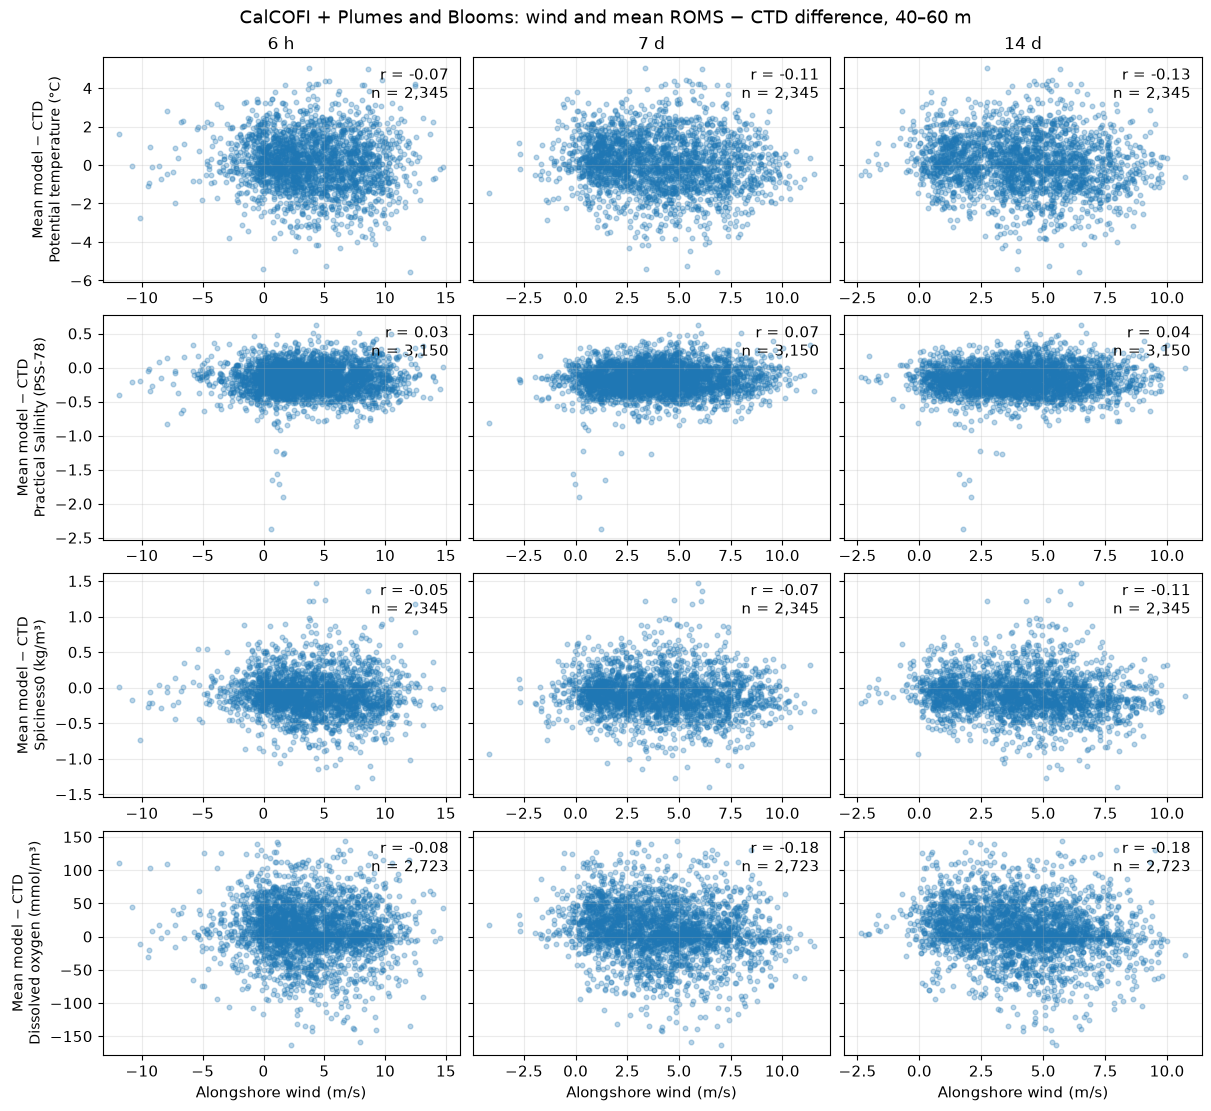

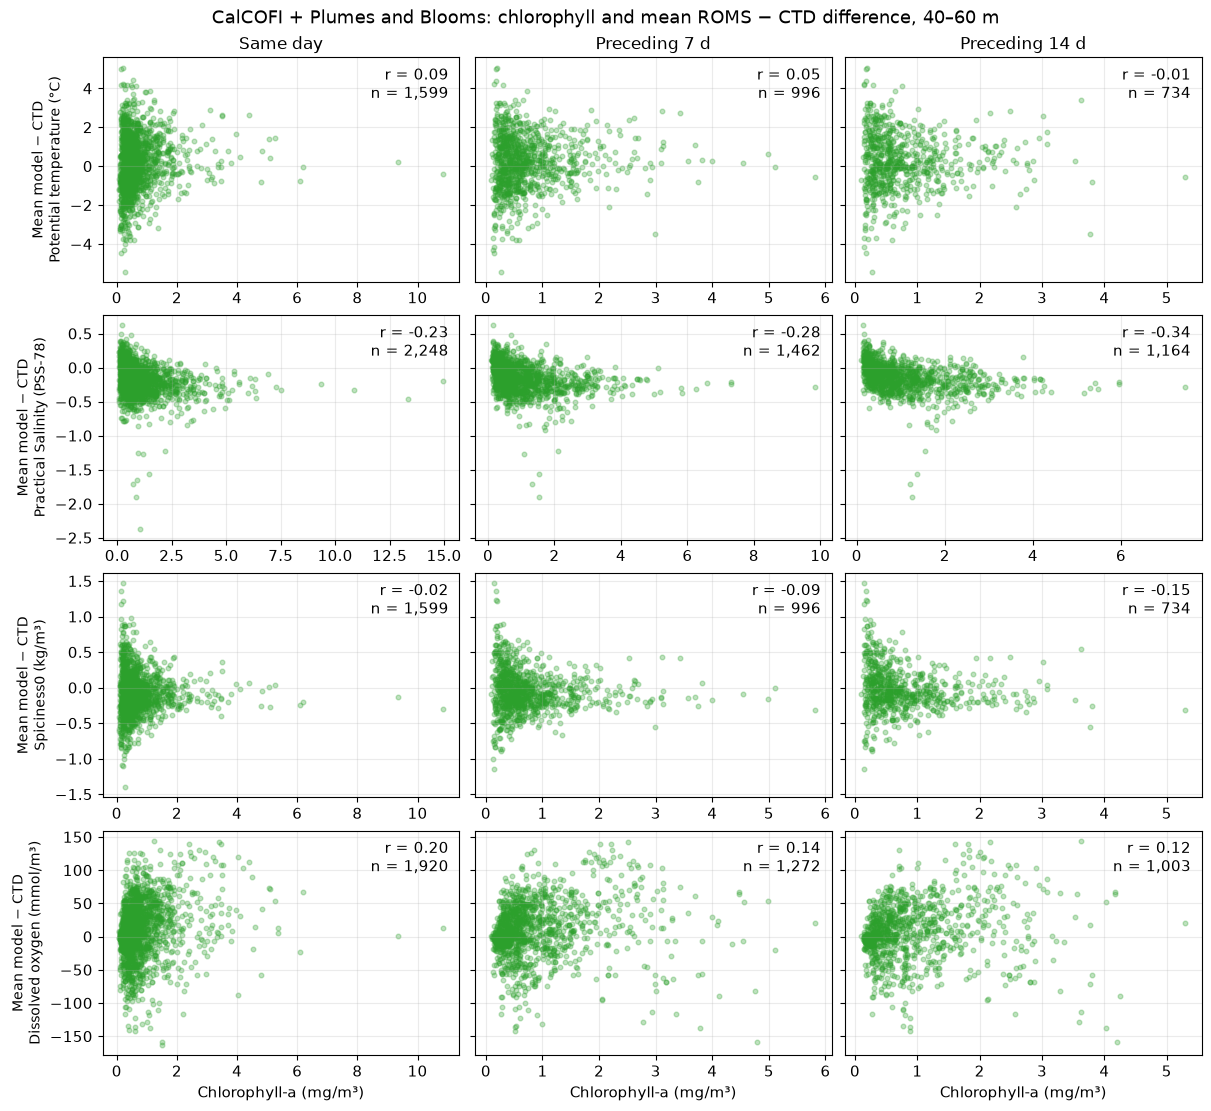

CalCOFI + Plumes and Blooms


,variable,window,pearson_r,n
0,temperature,wind_6h,-0.070,2345
1,temperature,wind_7d,-0.111,2345
2,temperature,wind_14d,-0.129,2345
3,salinity,wind_6h,0.033,3150
4,salinity,wind_7d,0.073,3150
5,salinity,wind_14d,0.036,3150
6,spiciness,wind_6h,-0.054,2345
7,spiciness,wind_7d,-0.074,2345
8,spiciness,wind_14d,-0.109,2345
9,oxygen,wind_6h,-0.079,2723


In [9]:
for group, sources in plot_groups.items():
    plot_data = conditions.loc[conditions['source'].isin(sources)]
    variables = plot_variables[group]
    wind_correlations = plot_correlations(
        plot_data, variables, group, wind_windows, 'Wind', 'Alongshore wind (m/s)', 'tab:blue',
    )
    chlorophyll_correlations = plot_correlations(
        plot_data, variables, group, chlorophyll_windows, 'Chlorophyll',
        'Chlorophyll-a (mg/m³)', 'tab:green',
    )
    correlations = pd.concat([wind_correlations, chlorophyll_correlations], ignore_index=True)
    correlations.to_csv(output_directory / f'{group}_correlations.csv', index=False)
    print(plot_titles[group])
    display(correlations.round({'pearson_r': 3}))
conditions.to_csv(output_directory / 'combined_cast_results.csv')